# Galectin method comparison: current vs alternative 1 vs alternative 2

Compares the three galectin pipelines on the same image folder:

| Method | Notebook | Cell unit | Puncta detector |
|---|---|---|---|
| **current** | `M17D_4channel_analysis.ipynb` | Cellpose cyto3 on orange+red (+ per-image green blob) | top-hat + per-cell percentile / mean+1.5·SD |
| **alt 1** | `M17D_galectin_alt1_green_blob.ipynb` | green blob from the GFP channel, nuclei counted inside, **1 row per image** | contrast ≥2× local cytoplasm + robust-noise (MAD) test |
| **alt 2** | `M17D_galectin_alt2_nucleus_circles.ipynb` | one **circular** cell per nucleus, per-cell rows + Excel-style per-image sum | circular LoG blobs, contrast ≥2× |

Run the three analysis notebooks on `COMPARE_FOLDER` first; this notebook reads only their CSVs and saved masks.

Checks:
1. Hard rules: rows with 0 nuclei / 0 nucleus area / 0 cytoplasm, and edge cells.
2. Nuclei per image against a hand count.
3. Spread and outliers within each condition.
4. Puncta detection on synthetic puncta of known contrast (spike-in).
5. Side-by-side puncta masks on real cells.
6. SCR vs MCCC1 summary for each method.

In [1]:
%matplotlib inline
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import ast, json, glob, io, contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage.segmentation import find_boundaries

pd.set_option("display.width", 200)
COMPARE_FOLDER = "galectin test images"
RESULTS = "Results"
RUN_SPIKE_IN = True  # check 4 takes ~1 min

CUR_CELL = os.path.join(RESULTS, f"{COMPARE_FOLDER}_galectin_LAMP1_lipidtox_analysis.csv")
CUR_BLOB = os.path.join(RESULTS, f"{COMPARE_FOLDER}_galectin_LAMP1_lipidtox_per_image_blob.csv")
ALT1_IMG = os.path.join(RESULTS, f"{COMPARE_FOLDER}_galectin_alt1_green_blob_per_image.csv")
ALT2_CELL = os.path.join(RESULTS, f"{COMPARE_FOLDER}_galectin_alt2_nucleus_circles_per_cell.csv")
ALT2_IMG = os.path.join(RESULTS, f"{COMPARE_FOLDER}_galectin_alt2_nucleus_circles_per_image_sum.csv")


def short(name):
    return (os.path.splitext(os.path.basename(name))[0]
            .replace("M17D_", "").replace("_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr", ""))


def condition(name):
    return short(name).split("_")[0]


tables = {}
for key, path in {"current per-cell": CUR_CELL, "current per-image blob": CUR_BLOB,
                  "alt1 per-image": ALT1_IMG, "alt2 per-cell": ALT2_CELL,
                  "alt2 per-image sum": ALT2_IMG}.items():
    df = pd.read_csv(path)
    df.insert(0, "Image", df["Filename"].map(short))
    df.insert(1, "Condition", df["Filename"].map(condition))
    tables[key] = df
    print(f"{key:24s} {len(df):3d} rows  <- {path}")

current per-cell          19 rows  <- Results/galectin test images_galectin_LAMP1_lipidtox_analysis.csv
current per-image blob    10 rows  <- Results/galectin test images_galectin_LAMP1_lipidtox_per_image_blob.csv
alt1 per-image            10 rows  <- Results/galectin test images_galectin_alt1_green_blob_per_image.csv
alt2 per-cell             13 rows  <- Results/galectin test images_galectin_alt2_nucleus_circles_per_cell.csv
alt2 per-image sum        10 rows  <- Results/galectin test images_galectin_alt2_nucleus_circles_per_image_sum.csv


## 1. Hard rules: 0 nuclei, 0 cytoplasm, edge

The current per-cell table removes "0 nucleus area" rows, but its nucleus mask also includes dim Hoechst haze in the cytoplasm (~37% of the field). Rows whose Cellpose nucleus count is 0 therefore still pass. The current tables have no `N_Nuclei` column per row for the blob, so its own `N_Nuclei` is used.

In [2]:
def rule_checks(df):
    n_nuc = df["N_Nuclei"] if "N_Nuclei" in df else pd.Series(np.nan, index=df.index)
    area = df["Cell_Area_px"] if "Cell_Area_px" in df else df["Blob_Area_px"]
    return pd.Series({
        "rows": len(df),
        "N_Nuclei == 0": int((n_nuc == 0).sum()),
        "Nucleus_Area == 0": int((df["Nucleus_Area_px"] == 0).sum()),
        "Cytoplasm == 0": int((df["Cytoplasm_Area_px"] == 0).sum()),
        "Cytoplasm < 10% of cell": int((df["Cytoplasm_Area_px"] < 0.10 * area).sum()),
        "Nucleus > 50% of cell": int((df["Nucleus_Area_px"] > 0.5 * area).sum()),
        "Touches edge": int(df.get("Touches_Image_Edge", pd.Series(False, index=df.index)).fillna(False).astype(bool).sum()),
    })


pd.DataFrame({k: rule_checks(v) for k, v in tables.items()}).T

,rows,N_Nuclei == 0,Nucleus_Area == 0,Cytoplasm == 0,Cytoplasm < 10% of cell,Nucleus > 50% of cell,Touches edge
current per-cell,19,7,0,0,3,14,0
current per-image blob,10,1,0,0,0,8,0
alt1 per-image,10,0,0,0,0,1,0
alt2 per-cell,13,0,0,0,0,3,0
alt2 per-image sum,10,0,0,0,0,3,0


## 2. Nuclei per image against a hand count

The hand count was made by viewing each test image's Hoechst + galectin-GFP overlay. It counts complete (not edge-touching) bright galectin-GFP cells and the nuclei inside them. Please check it against your own reading of the images.
- MCCC1_05: one green blob holding two GFP-filled nuclei.
- MCCC1_08: the galectin cell's nucleus is dim in Hoechst. Plain Cellpose misses it, so the alternatives use a log-Hoechst rescue.
- SCR_02: two green cells, the upper one with two nuclei.
- SCR_03: two complete cells; the top-left cell is cut by the border.

In [3]:
HAND_COUNT = {  # image: (complete bright green cells/blobs, nuclei in them)
    "MCCC1_03": (1, 1), "MCCC1_04": (1, 1), "MCCC1_05": (1, 2), "MCCC1_06": (1, 1),
    "MCCC1_07": (1, 1), "MCCC1_08": (1, 1), "SCR_01": (1, 1), "SCR_02": (2, 3),
    "SCR_03": (2, 2), "SCR_04": (1, 1),
}
gt = pd.DataFrame(HAND_COUNT, index=["hand_cells", "hand_nuclei"]).T
cmp = gt.copy()
cmp["current: per-cell rows"] = tables["current per-cell"].groupby("Image").size()
cmp["current: rows with 0 nuclei"] = tables["current per-cell"].groupby("Image")["N_Nuclei"].apply(lambda s: int((s == 0).sum()))
cmp["current blob: N_Nuclei"] = tables["current per-image blob"].set_index("Image")["N_Nuclei"]
cmp["alt1: N_Nuclei"] = tables["alt1 per-image"].set_index("Image")["N_Nuclei"]
cmp["alt2: cells (=nuclei)"] = tables["alt2 per-image sum"].set_index("Image")["N_Cells"]
cmp = cmp.fillna(0).astype(int)
display(cmp)
score = {}
for col in ["current: per-cell rows", "current blob: N_Nuclei", "alt1: N_Nuclei", "alt2: cells (=nuclei)"]:
    err = (cmp[col] - cmp["hand_nuclei"])
    score[col] = {"images exactly right": int((err == 0).sum()), "total |error|": int(err.abs().sum()),
                  "over-counted": int(err.clip(lower=0).sum()), "missed": int((-err).clip(lower=0).sum())}
pd.DataFrame(score).T

,hand_cells,hand_nuclei,current: per-cell rows,current: rows with 0 nuclei,current blob: N_Nuclei,alt1: N_Nuclei,alt2: cells (=nuclei)
MCCC1_03,1,1,2,1,1,1,1
MCCC1_04,1,1,3,3,1,1,1
MCCC1_05,1,2,2,0,3,2,2
MCCC1_06,1,1,1,0,1,1,1
MCCC1_07,1,1,2,0,2,1,1
MCCC1_08,1,1,1,1,0,1,1
SCR_01,1,1,1,0,1,1,1
SCR_02,2,3,3,1,3,3,2
SCR_03,2,2,3,1,4,2,2
SCR_04,1,1,1,0,1,1,1


,images exactly right,total |error|,over-counted,missed
current: per-cell rows,6,5,5,0
current blob: N_Nuclei,6,5,4,1
alt1: N_Nuclei,10,0,0,0
alt2: cells (=nuclei),9,1,0,1


`alt2` can be below the hand count for a reason that is not a segmentation error. Its eligibility rule (red and orange present) is applied per circular cell, so one nucleus of a two-nucleus cell can be dropped as "no red" (see `cell_eligibility.csv`).

## 3. Spread and outliers within each condition

Image-level galectin dots per nucleus, the read-out every method can produce. For the current pipeline it is the per-cell table summed per image (dots ÷ exported rows), plus its per-image blob (dots ÷ `N_Nuclei`, which is infinite when `N_Nuclei` = 0). Lower within-condition CV means less measurement noise, but with 4–6 images per condition treat it as a sanity check, not a test. Outliers use Tukey fences (1.5·IQR) on the per-cell tables.

In [4]:
cur = tables["current per-cell"]
cur_img = cur.groupby(["Image", "Condition"]).agg(dots=("N_Green_Dots", "sum"), rows=("Cell_ID", "size")).reset_index()
cur_img["dots_per_unit"] = cur_img["dots"] / cur_img["rows"]
cb = tables["current per-image blob"].copy()
cb["dots_per_unit"] = cb["N_Green_Dots"] / cb["N_Nuclei"].replace(0, np.nan)
per_image = {
    "current per-cell (dots / row)": cur_img,
    "current blob (dots / nucleus)": cb,
    "alt1 (dots / nucleus)": tables["alt1 per-image"].assign(dots_per_unit=lambda d: d["Green_Dots_per_Nucleus"]),
    "alt2 sum (dots / nucleus)": tables["alt2 per-image sum"].assign(dots_per_unit=lambda d: d["Green_Dots_per_Nucleus"]),
}
rows = []
for name, d in per_image.items():
    for cond, g in d.groupby("Condition"):
        v = g["dots_per_unit"]
        rows.append({"method": name, "condition": cond, "n images": int(v.notna().sum()),
                     "undefined (0 nuclei)": int(v.isna().sum()),
                     "mean": round(v.mean(), 2), "SD": round(v.std(), 2), "CV": round(v.std() / v.mean(), 2)})
display(pd.DataFrame(rows))


def tukey_outliers(df, cols):
    out = {}
    for c in cols:
        x = df[c]
        q1, q3 = x.quantile([0.25, 0.75])
        out[c] = int(((x < q1 - 1.5 * (q3 - q1)) | (x > q3 + 1.5 * (q3 - q1))).sum())
    return out


cols = ["Cell_Area_px", "Cytoplasm_Area_px", "Nucleus_Area_px", "N_Green_Dots", "Green_Dot_MFI"]
pd.DataFrame({k: {**tukey_outliers(tables[k], cols), "rows": len(tables[k])}
              for k in ["current per-cell", "alt2 per-cell"]}).T

,method,condition,n images,undefined (0 nuclei),mean,SD,CV
0,current per-cell (dots / row),MCCC1,6,0,22.50,18.38,0.82
1,current per-cell (dots / row),SCR,4,0,36.33,32.86,0.90
2,current blob (dots / nucleus),MCCC1,5,1,23.43,14.45,0.62
3,current blob (dots / nucleus),SCR,4,0,28.12,34.79,1.24
4,alt1 (dots / nucleus),MCCC1,6,0,29.00,14.01,0.48
5,alt1 (dots / nucleus),SCR,4,0,10.42,11.26,1.08
6,alt2 sum (dots / nucleus),MCCC1,6,0,32.83,14.43,0.44
7,alt2 sum (dots / nucleus),SCR,4,0,11.12,12.04,1.08


,Cell_Area_px,Cytoplasm_Area_px,Nucleus_Area_px,N_Green_Dots,Green_Dot_MFI,rows
current per-cell,0,1,0,3,0,19
alt2 per-cell,1,1,0,0,0,13


## 4. Puncta detectors on synthetic puncta (spike-in)

The question "are dim green dots being counted?" can be answered with puncta whose brightness is known. Gaussian puncta (σ = 2 px) with a known raw peak contrast over the local cytoplasm are added at dot-free positions in every complete green cell. All three detectors then run on **the same cell masks** (alt 1 green blobs). A punctum counts as detected if any detected pixel lies within 3 px of its centre.

A good detector shows a sharp step: ~0% detected below its cutoff, ~100% above it, at the same contrast in every cell.

level,1.25x,1.5x,1.75x,2.0x,2.5x,3.0x,4.0x
detector,,,,,,,
alt1 contrast+MAD,0.0,0.0,0.0,3.8,72.6,97.9,100.0
alt2 LoG circles,0.0,0.0,0.0,3.8,74.0,99.7,100.0
current,4.5,9.4,18.8,25.0,47.9,69.1,91.0


Contrast at which each cell reaches 50% detection (same value in every cell = consistent):


detector,alt1 contrast+MAD,alt2 LoG circles,current
cell,,,
MCCC1_03#1,2.5,2.5,3.00
MCCC1_04#1,2.5,2.5,2.50
MCCC1_05#1,2.5,2.5,1.75
MCCC1_06#1,2.5,2.5,2.50
MCCC1_07#2,2.5,2.5,3.00
MCCC1_08#1,2.5,2.5,4.00
SCR_01#1,2.5,2.5,1.50
SCR_02#1,2.5,2.5,1.75
SCR_02#2,2.5,2.5,2.00


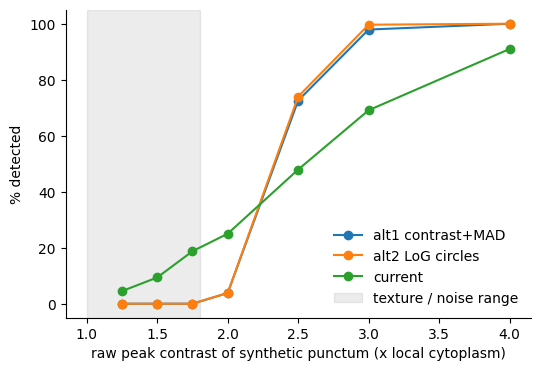

In [5]:
def notebook_namespace(path, skip_last=2):
    """Exec a notebook's function/parameter cells (not its driver) without loading Cellpose."""
    nb = json.load(open(path))
    code = ["".join(c["source"]) for c in nb["cells"] if c["cell_type"] == "code"][:-skip_last]
    src = "\n\n".join(code).replace('nuc_model = load_cellpose_model("nuclei")', "nuc_model = None")
    src = "\n".join("" if l.lstrip().startswith(("%", "!")) else l for l in src.splitlines())
    ns = {}
    with contextlib.redirect_stdout(io.StringIO()):
        exec(compile(src, path, "exec"), ns)
    return ns


def current_dot_detector(path="M17D_4channel_analysis.ipynb"):
    """The current notebook's detect_green_dots with its own parameters."""
    nb = json.load(open(path))
    src = "\n".join("".join(c["source"]) for c in nb["cells"] if c["cell_type"] == "code")
    # tolerate the unclosed print( in the per-image cell, if still present
    src = src.replace('f"(fill >= {GREEN_FILL_FRAC})"\n', 'f"(fill >= {GREEN_FILL_FRAC})")\n')
    tree = ast.parse("\n".join("" if l.lstrip().startswith("%") else l for l in src.splitlines()))
    wanted = {"normalize_image", "_disk_filter", "disk_opening", "white_tophat_disk",
              "binary_closing_disk", "bridge_small_gaps", "detect_green_dots"}
    imports = [n for n in tree.body if isinstance(n, (ast.Import, ast.ImportFrom))]
    consts = [n for n in tree.body if isinstance(n, ast.Assign) and any(
        isinstance(t, ast.Name) and t.id.startswith(("GREEN_", "STRUCTURE_")) for t in n.targets)]
    funcs = [n for n in tree.body if isinstance(n, ast.FunctionDef) and n.name in wanted]
    ns = {}
    exec(compile(ast.fix_missing_locations(ast.Module(body=imports + consts + funcs, type_ignores=[])),
                 path, "exec"), ns)
    return lambda green_raw, cells: ns["detect_green_dots"](ns["normalize_image"](green_raw), cells)


if RUN_SPIKE_IN:
    alt1 = notebook_namespace("M17D_galectin_alt1_green_blob.ipynb")
    alt2 = notebook_namespace("M17D_galectin_alt2_nucleus_circles.ipynb")
    detectors = {"current": current_dot_detector(),
                 "alt1 contrast+MAD": lambda g, c: alt1["detect_green_dots"](g, c)[0],
                 "alt2 LoG circles": lambda g, c: alt2["detect_green_dots"](g, c)[0]}
    LEVELS, N_SPIKES, REPEATS, SIGMA = [1.25, 1.5, 1.75, 2.0, 2.5, 3.0, 4.0], 12, 2, 2.0
    rng = np.random.default_rng(0)
    r = int(4 * SIGMA)
    yy, xx = np.mgrid[-r:r + 1, -r:r + 1]
    kernel = np.exp(-(yy ** 2 + xx ** 2) / (2 * SIGMA ** 2))
    records = []
    for path in sorted(glob.glob(os.path.join(COMPARE_FOLDER, "*.czi"))):
        raw = alt1["load_four_channels"](path)
        blobs, _ = alt1["segment_green_cells"](raw["green"])
        edge = alt1["touches_image_edge"](blobs)
        _, bg, contrast = alt1["local_cytoplasm_background"](raw["green"], blobs)
        for bid in range(1, int(blobs.max()) + 1):
            if bid in edge:
                continue
            cell = blobs == bid
            safe = ndi.binary_erosion(cell, iterations=12) & ~ndi.binary_dilation(contrast > 1.4, iterations=10)
            ys, xs = np.nonzero(safe)
            for rep in range(REPEATS):
                for level in LEVELS:
                    pos = []
                    for i in rng.permutation(len(ys)):
                        p = (ys[i], xs[i])
                        if all((p[0] - q[0]) ** 2 + (p[1] - q[1]) ** 2 > 24 ** 2 for q in pos):
                            pos.append(p)
                        if len(pos) == N_SPIKES:
                            break
                    spiked = raw["green"].astype(np.float64)
                    for (y, x) in pos:
                        spiked[y - r:y + r + 1, x - r:x + r + 1] += (level - 1) * bg[y, x] * kernel
                    spiked = np.clip(spiked, 0, 65535).astype(np.uint16)
                    for name, det in detectors.items():
                        near = ndi.binary_dilation(det(spiked, cell.astype(np.int32)), iterations=3)
                        records.append({"detector": name, "cell": f"{short(path)}#{bid}", "level": level,
                                        "detected": np.mean([near[p] for p in pos])})
    spike = pd.DataFrame(records)
    curve = spike.groupby(["detector", "level"])["detected"].mean().unstack()
    display((100 * curve).round(1).rename(columns=lambda c: f"{c}x"))

    def c50(g):
        m = g.groupby("level")["detected"].mean()
        return m[m >= 0.5].index.min() if (m >= 0.5).any() else np.nan

    per_cell = spike.groupby(["detector", "cell"]).apply(c50, include_groups=False).unstack(0)
    print("Contrast at which each cell reaches 50% detection (same value in every cell = consistent):")
    display(per_cell)
    fig, ax = plt.subplots(figsize=(6, 4))
    for name, row in curve.iterrows():
        ax.plot(row.index, 100 * row.values, marker="o", label=name)
    ax.axvspan(1.0, 1.8, color="grey", alpha=0.15, label="texture / noise range")
    ax.set_xlabel("raw peak contrast of synthetic punctum (x local cytoplasm)")
    ax.set_ylabel("% detected")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    plt.show()

## 5. Puncta masks on real cells

Magenta = detected puncta. Yellow (alt 2) = the circular cell mask. In SCR_01, a cell with few puncta, the current percentile threshold flags texture across the whole cell. In MCCC1_08 it misses the bright cluster on the left. Both alternatives outline the bright puncta.

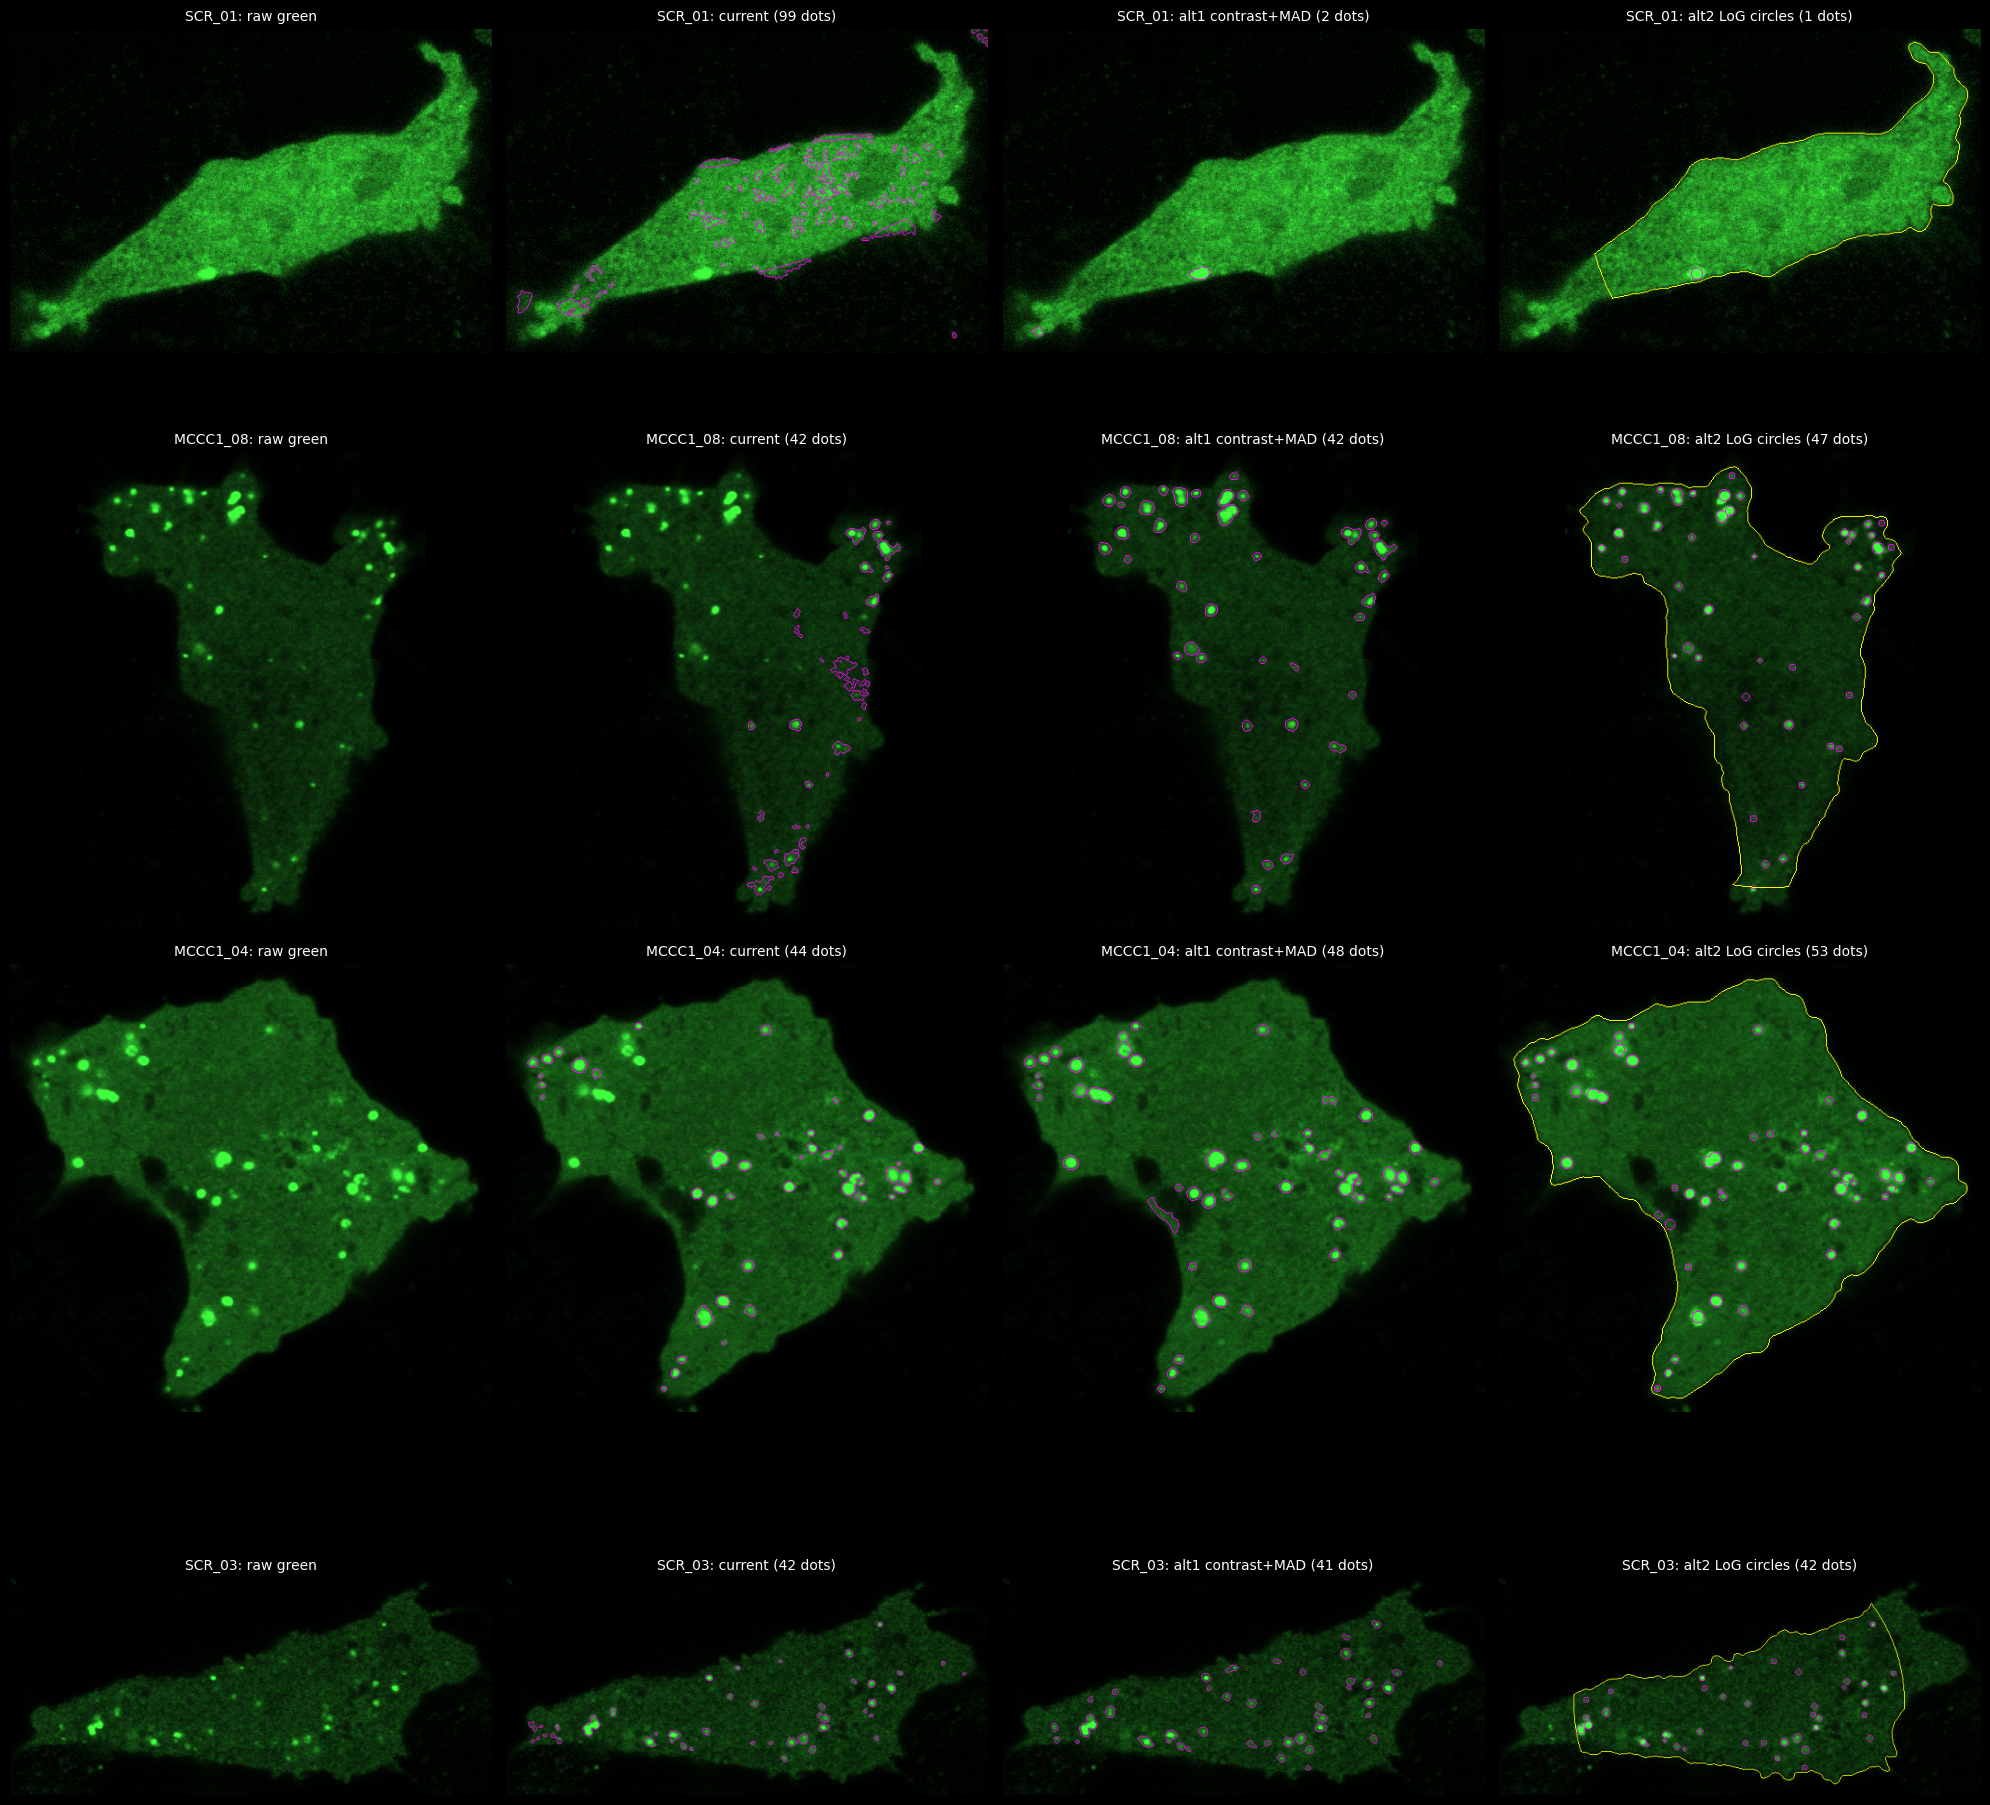

In [6]:
SHOW = ["SCR_01", "MCCC1_08", "MCCC1_04", "SCR_03"]
stems = {short(p): os.path.splitext(os.path.basename(p))[0]
         for p in glob.glob(os.path.join(COMPARE_FOLDER, "*.czi"))}
m_cur = os.path.join(RESULTS, "masks", COMPARE_FOLDER)
m_a1 = os.path.join(RESULTS, "masks_alt1_green_blob", COMPARE_FOLDER)
m_a2 = os.path.join(RESULTS, "masks_alt2_nucleus_circles", COMPARE_FOLDER)
import czifile
fig, axs = plt.subplots(len(SHOW), 4, figsize=(20, 5 * len(SHOW)))
fig.patch.set_facecolor("black")
for row, key in zip(axs, SHOW):
    stem = stems[key]
    green = np.squeeze(czifile.CziFile(os.path.join(COMPARE_FOLDER, stem + ".czi")).asarray())[2].astype(float)
    blobs = np.load(os.path.join(m_a1, stem, "green_blobs.npy"))
    big = blobs == (np.bincount(blobs.ravel())[1:].argmax() + 1)
    ys, xs = np.nonzero(big)
    sl = (slice(max(ys.min() - 15, 0), ys.max() + 15), slice(max(xs.min() - 15, 0), xs.max() + 15))
    crop = green[sl]
    lo, hi = np.percentile(crop, 1), np.percentile(crop[big[sl]], 99.7)
    gg = np.clip((crop - lo) / (hi - lo), 0, 1) ** 0.7
    base = np.dstack([gg * 0.25, gg, gg * 0.25])
    masks = [("raw green", None, None),
             ("current", np.load(os.path.join(m_cur, stem, "green_dots.npy")), None),
             ("alt1 contrast+MAD", np.load(os.path.join(m_a1, stem, "green_dots.npy")), None),
             ("alt2 LoG circles", np.load(os.path.join(m_a2, stem, "green_dots.npy")),
              np.load(os.path.join(m_a2, stem, "circular_cells.npy")))]
    for ax, (name, dots, cells) in zip(row, masks):
        im = base.copy()
        title = f"{key}: {name}"
        if dots is not None:
            im[find_boundaries(dots[sl], mode="outer")] = (1, 0, 1)
            title += f" ({int(ndi.label(dots[sl] & big[sl])[1])} dots)"
        if cells is not None:
            im[find_boundaries(cells[sl] > 0, mode="inner")] = (1, 1, 0)
        ax.imshow(im)
        ax.set_title(title, color="white", fontsize=10)
        ax.axis("off")
plt.tight_layout()
plt.show()

## 6. SCR vs MCCC1 per method

Mean ± SD over images (n = images). With 4 SCR and 6 MCCC1 test images, this only shows whether each method gives a stable read-out. It is not a result.

In [7]:
metrics = {"Green dots per nucleus": "dots_per_unit",
           "Galectin dot area fraction": "Green_Dot_Area_Fraction",
           "Green dot MFI (raw)": "Green_Dot_MFI"}
cur_img2 = cur.groupby(["Image", "Condition"]).agg(
    dots=("N_Green_Dots", "sum"), rows=("Cell_ID", "size"), dot_area=("Green_Dot_Area_px", "sum"),
    area=("Cell_Area_px", "sum"), dot_mfi=("Green_Dot_MFI", "mean")).reset_index()
cur_img2["dots_per_unit"] = cur_img2["dots"] / cur_img2["rows"]
cur_img2["Green_Dot_Area_Fraction"] = cur_img2["dot_area"] / cur_img2["area"]
cur_img2["Green_Dot_MFI"] = cur_img2["dot_mfi"]
cb2 = cb.assign(Green_Dot_Area_Fraction=cb["Green_Dot_Area_px"] / cb["Blob_Area_px"])
sources = {"current per-cell": cur_img2, "current blob": cb2,
           "alt1": per_image["alt1 (dots / nucleus)"], "alt2 sum": per_image["alt2 sum (dots / nucleus)"]}
out = []
for mname, col in metrics.items():
    for sname, d in sources.items():
        g = d.groupby("Condition")[col]
        s = g.agg(["mean", "std", "count"])
        out.append({"metric": mname, "method": sname,
                    **{f"{c} mean±SD (n)": f"{s.loc[c, 'mean']:.3g} ± {s.loc[c, 'std']:.2g} ({int(s.loc[c, 'count'])})"
                       for c in s.index}})
pd.DataFrame(out)

,metric,method,MCCC1 mean±SD (n),SCR mean±SD (n)
0,Green dots per nucleus,current per-cell,22.5 ± 18 (6),36.3 ± 33 (4)
1,Green dots per nucleus,current blob,23.4 ± 14 (5),28.1 ± 35 (4)
2,Green dots per nucleus,alt1,29 ± 14 (6),10.4 ± 11 (4)
3,Green dots per nucleus,alt2 sum,32.8 ± 14 (6),11.1 ± 12 (4)
4,Galectin dot area fraction,current per-cell,0.0286 ± 0.0077 (6),0.0322 ± 0.018 (4)
5,Galectin dot area fraction,current blob,0.0248 ± 0.0067 (6),0.0203 ± 0.014 (4)
6,Galectin dot area fraction,alt1,0.0395 ± 0.013 (6),0.0178 ± 0.013 (4)
7,Galectin dot area fraction,alt2 sum,0.0217 ± 0.0056 (6),0.00937 ± 0.0082 (4)
8,Green dot MFI (raw),current per-cell,2.45e+04 ± 1.2e+04 (6),1.41e+04 ± 8.7e+03 (4)
9,Green dot MFI (raw),current blob,3.35e+04 ± 9.8e+03 (6),1.38e+04 ± 6.1e+03 (4)


## Conclusion (test images, 2026-11-06)

**Recommended: alternative 1 (green blob, one row per image), puncta by contrast.**

| | current | alt 1 green blob | alt 2 circles |
|---|---|---|---|
| Images whose nucleus count matches the hand count | 6 / 10 | **10 / 10** | 9 / 10 |
| Exported rows with 0 nuclei | 7 of 19 (cells), 1 of 10 (blob) | **0** | **0** |
| Rows per real cell | 19 rows for 14 nuclei (fragments) | 1 per image | 1 per nucleus |
| Synthetic puncta ≤1.75× counted (dim dots) | 5–19% | **0%** | **0%** |
| Synthetic 3× puncta found | 69% | 98% | 100% |
| 50%-detection contrast across cells | 1.5–4× | **2.5× in every cell** | **2.5× in every cell** |
| Within-condition CV, dots per nucleus (MCCC1 / SCR) | 0.62 / 1.24 (blob) | 0.48 / 1.08 | 0.44 / 1.08 |

- **Cell unit.** Taking galectin cells from the green channel and counting nuclei inside is the only approach that matched the hand count in every image. It also removes Cellpose fragments, edge cells and dim low-expressing cells by construction.
- **Puncta.** Both new detectors give the same, consistent cutoff. Alternative 1's mask keeps each punctum's real shape, so its dot area is measured rather than a fitted disk. The current percentile threshold counts background texture in dot-poor cells (SCR_01: ~80–100 "dots" in a cell with ~2 real puncta) and misses bright clusters (MCCC1_08).
- **Circular masks (alt 2).** At 2.5× nucleus radius they keep about 95% of each cell on average but cut up to ~23% of elongated cells. They did not reduce spread (dot-density CV 0.47 with circles vs 0.45 without). The per-cell red/orange rule can also drop one nucleus of a two-nucleus cell (SCR_02). If per-cell rows are needed, use alt 2 with `CIRCLE_RADIUS_SCALE = None`.

**Caveats.** These are 10 test images, and the hand count was made from overlays and should be checked by eye. The spike-in shows the detectors are *consistent*, not which cutoff is biologically right (`DOT_MIN_CONTRAST` sets it). The SCR vs MCCC1 direction **reverses** between the current method (SCR higher, inflated by texture counted as dots) and both alternatives (MCCC1 about 3× higher). Confirm this on the full dated folders before drawing conclusions.